# Exploratory Data Analysis

Analyze all supplied Waymo segments. Whole segments remain in their supplied splits to avoid adjacent-frame leakage. Red = vehicle, blue = pedestrian, green = cyclist. The implementation is in `run_eda.py` and `analysis_utils.py`.

In [1]:
from run_eda import analyze, display_instances

# display_instances draws normalized boxes with a color for each class.
analyze()

train {"segments": 86, "frames": 1719, "class_counts": {"1": 29710, "2": 8355, "4": 214}, "image_shapes": {"(640, 640, 3)": 1719}, "mean_objects": 22.268179173938336, "brightness_mean": 98.02163175649831, "brightness_std": 27.35666986490591, "box_area_median": 0.0006499096534078319}
val {"segments": 10, "frames": 198, "class_counts": {"2": 2068, "1": 4953, "4": 56}, "image_shapes": {"(640, 640, 3)": 198}, "mean_objects": 35.74242424242424, "brightness_mean": 116.56433612656512, "brightness_std": 11.410335784931064, "box_area_median": 0.0003564511151523675}
test {"segments": 3, "frames": 596, "class_counts": {"1": 8867, "2": 844}, "image_shapes": {"(640, 640, 3)": 596}, "mean_objects": 16.293624161073826, "brightness_mean": 77.4104942673378, "brightness_std": 41.370414753707266, "box_area_median": 0.007432738880822853}


In [2]:
import json
from pathlib import Path

statistics = json.loads(Path("artifacts/eda/statistics.json").read_text())
for split, values in statistics.items():
    print(split, {k: v for k, v in values.items() if k != "files"})

train {'segments': 86, 'frames': 1719, 'class_counts': {'1': 29710, '2': 8355, '4': 214}, 'image_shapes': {'(640, 640, 3)': 1719}, 'mean_objects': 22.268179173938336, 'brightness_mean': 98.02163175649831, 'brightness_std': 27.35666986490591, 'box_area_median': 0.0006499096534078319}
val {'segments': 10, 'frames': 198, 'class_counts': {'2': 2068, '1': 4953, '4': 56}, 'image_shapes': {'(640, 640, 3)': 198}, 'mean_objects': 35.74242424242424, 'brightness_mean': 116.56433612656512, 'brightness_std': 11.410335784931064, 'box_area_median': 0.0003564511151523675}
test {'segments': 3, 'frames': 596, 'class_counts': {'1': 8867, '2': 844}, 'image_shapes': {'(640, 640, 3)': 596}, 'mean_objects': 16.293624161073826, 'brightness_mean': 77.4104942673378, 'brightness_std': 41.370414753707266, 'box_area_median': 0.007432738880822853}


## Ten sampled training images

Reservoir sampling with seed 42 spans all training segments.

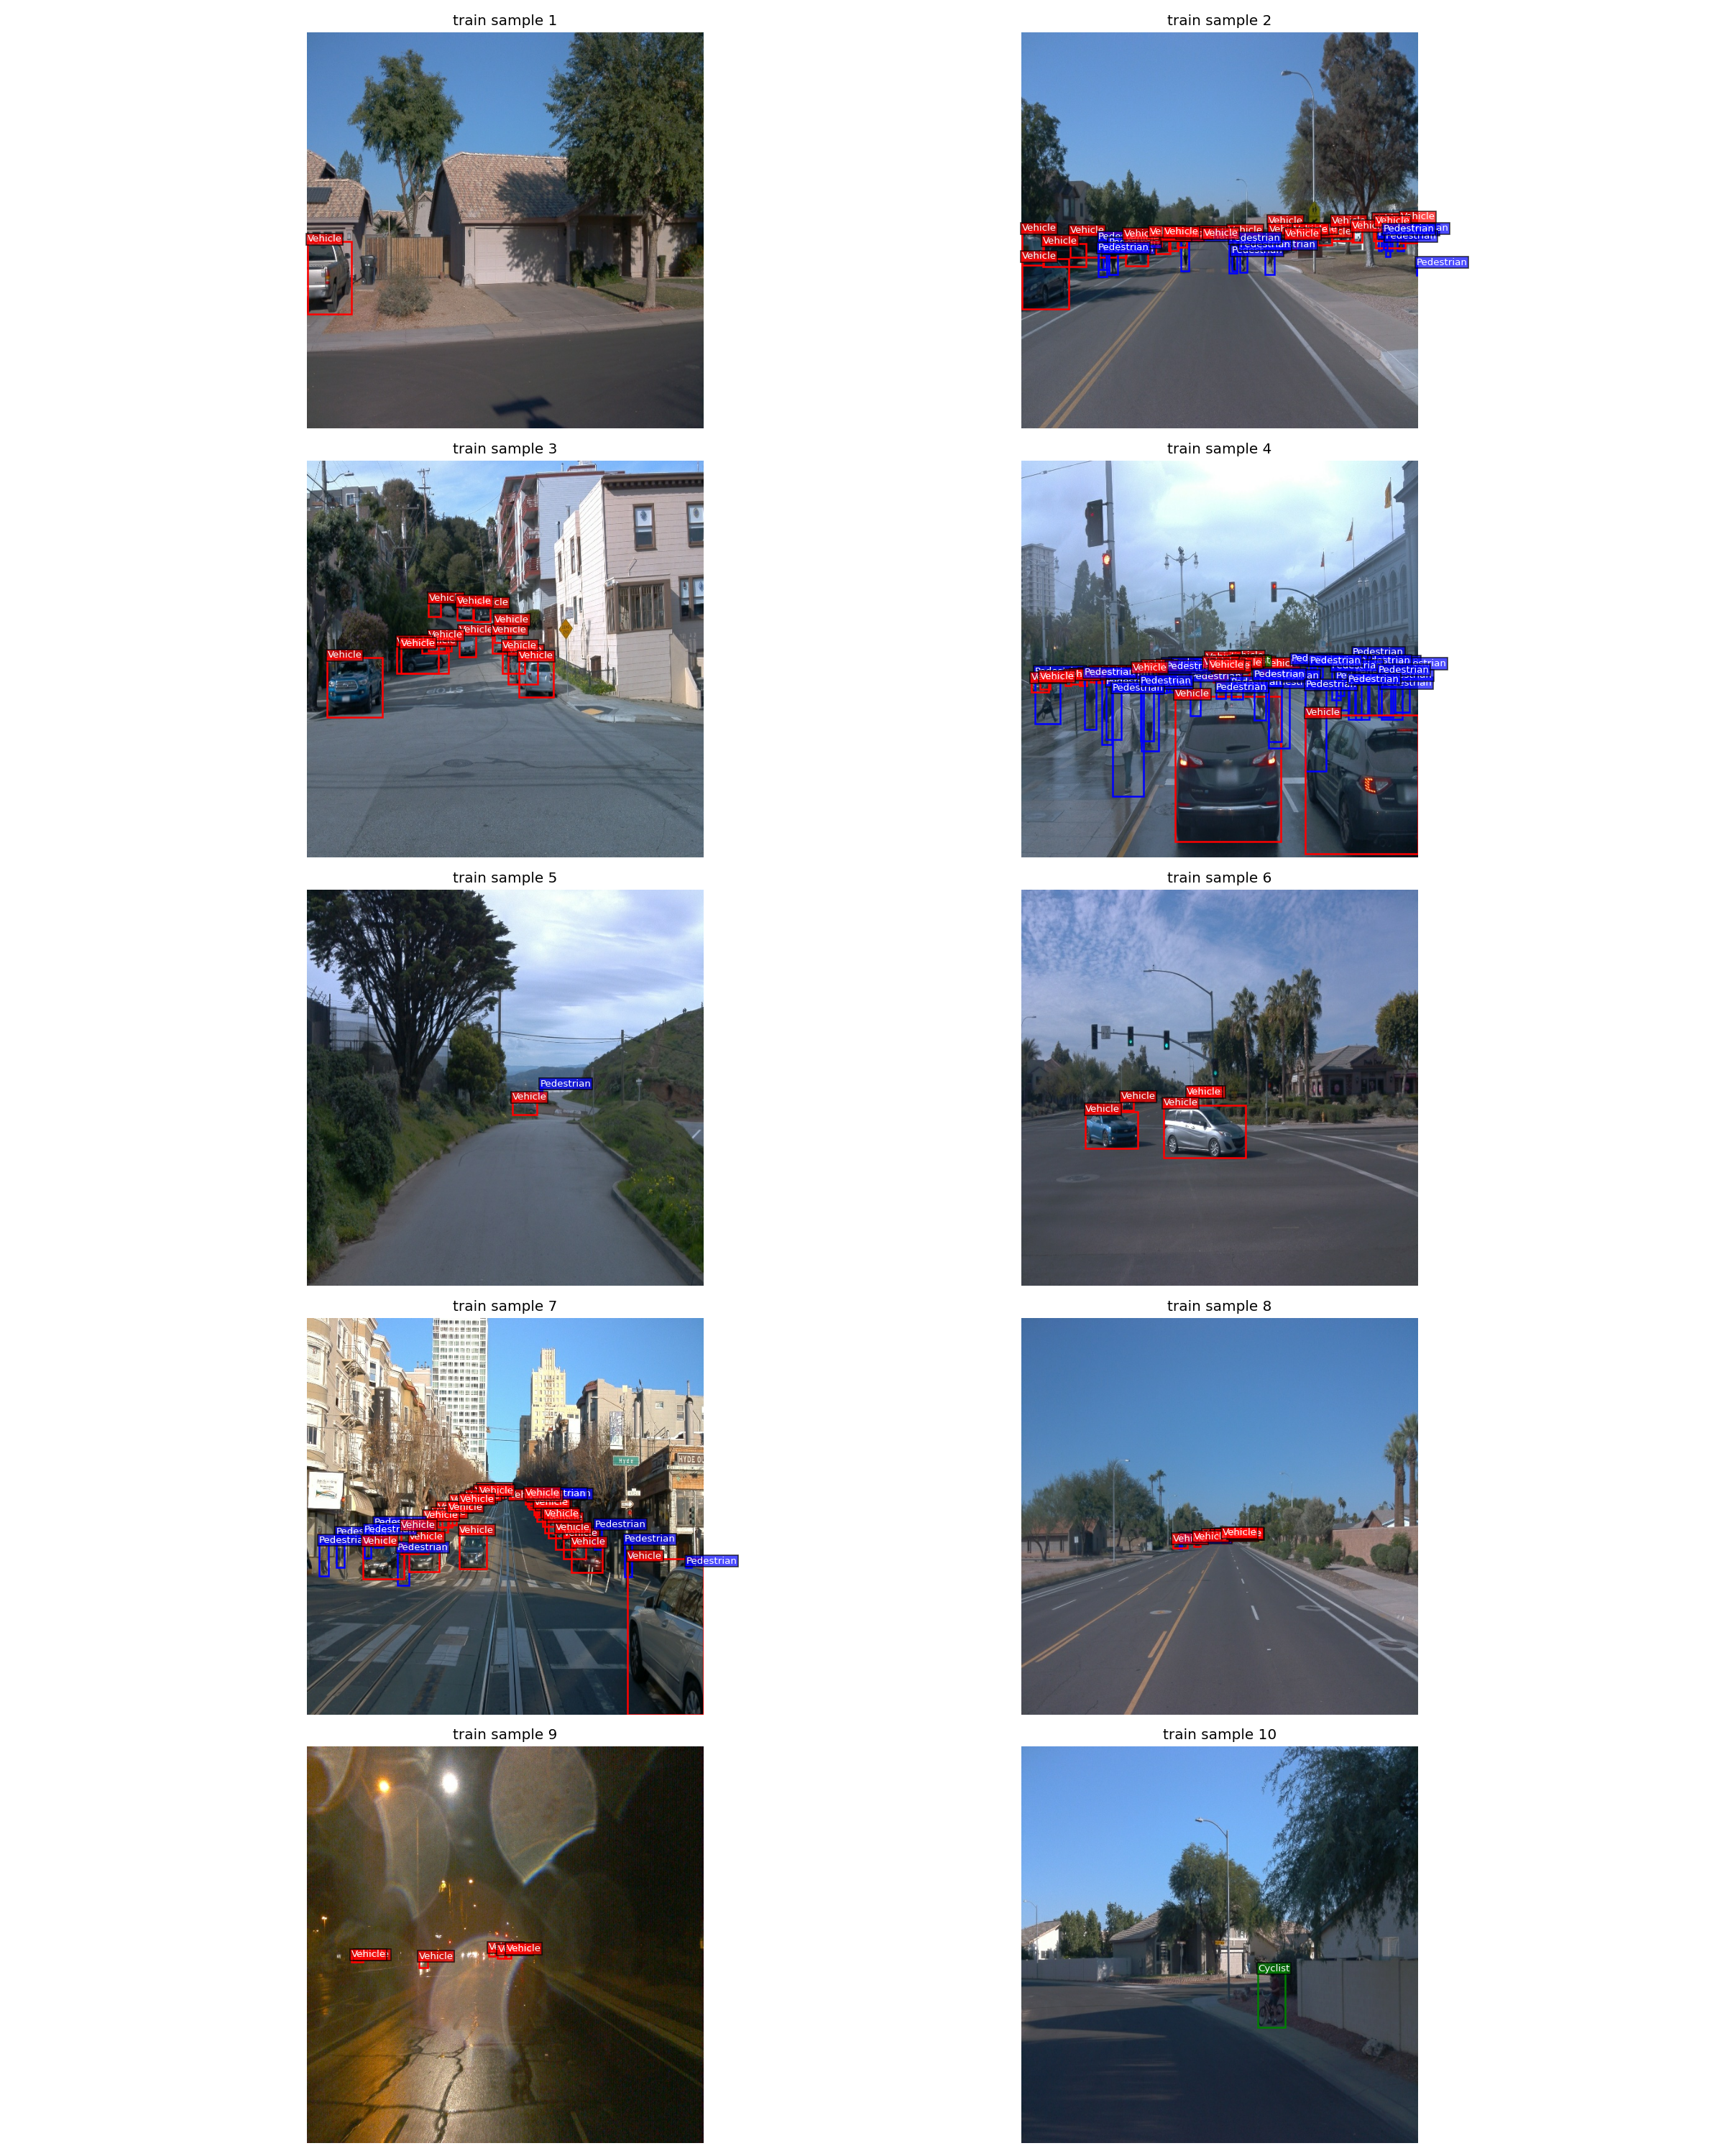

In [3]:
from IPython.display import Image, display
display(Image(filename="artifacts/eda/train_samples.png"))

## Class distribution and image variability

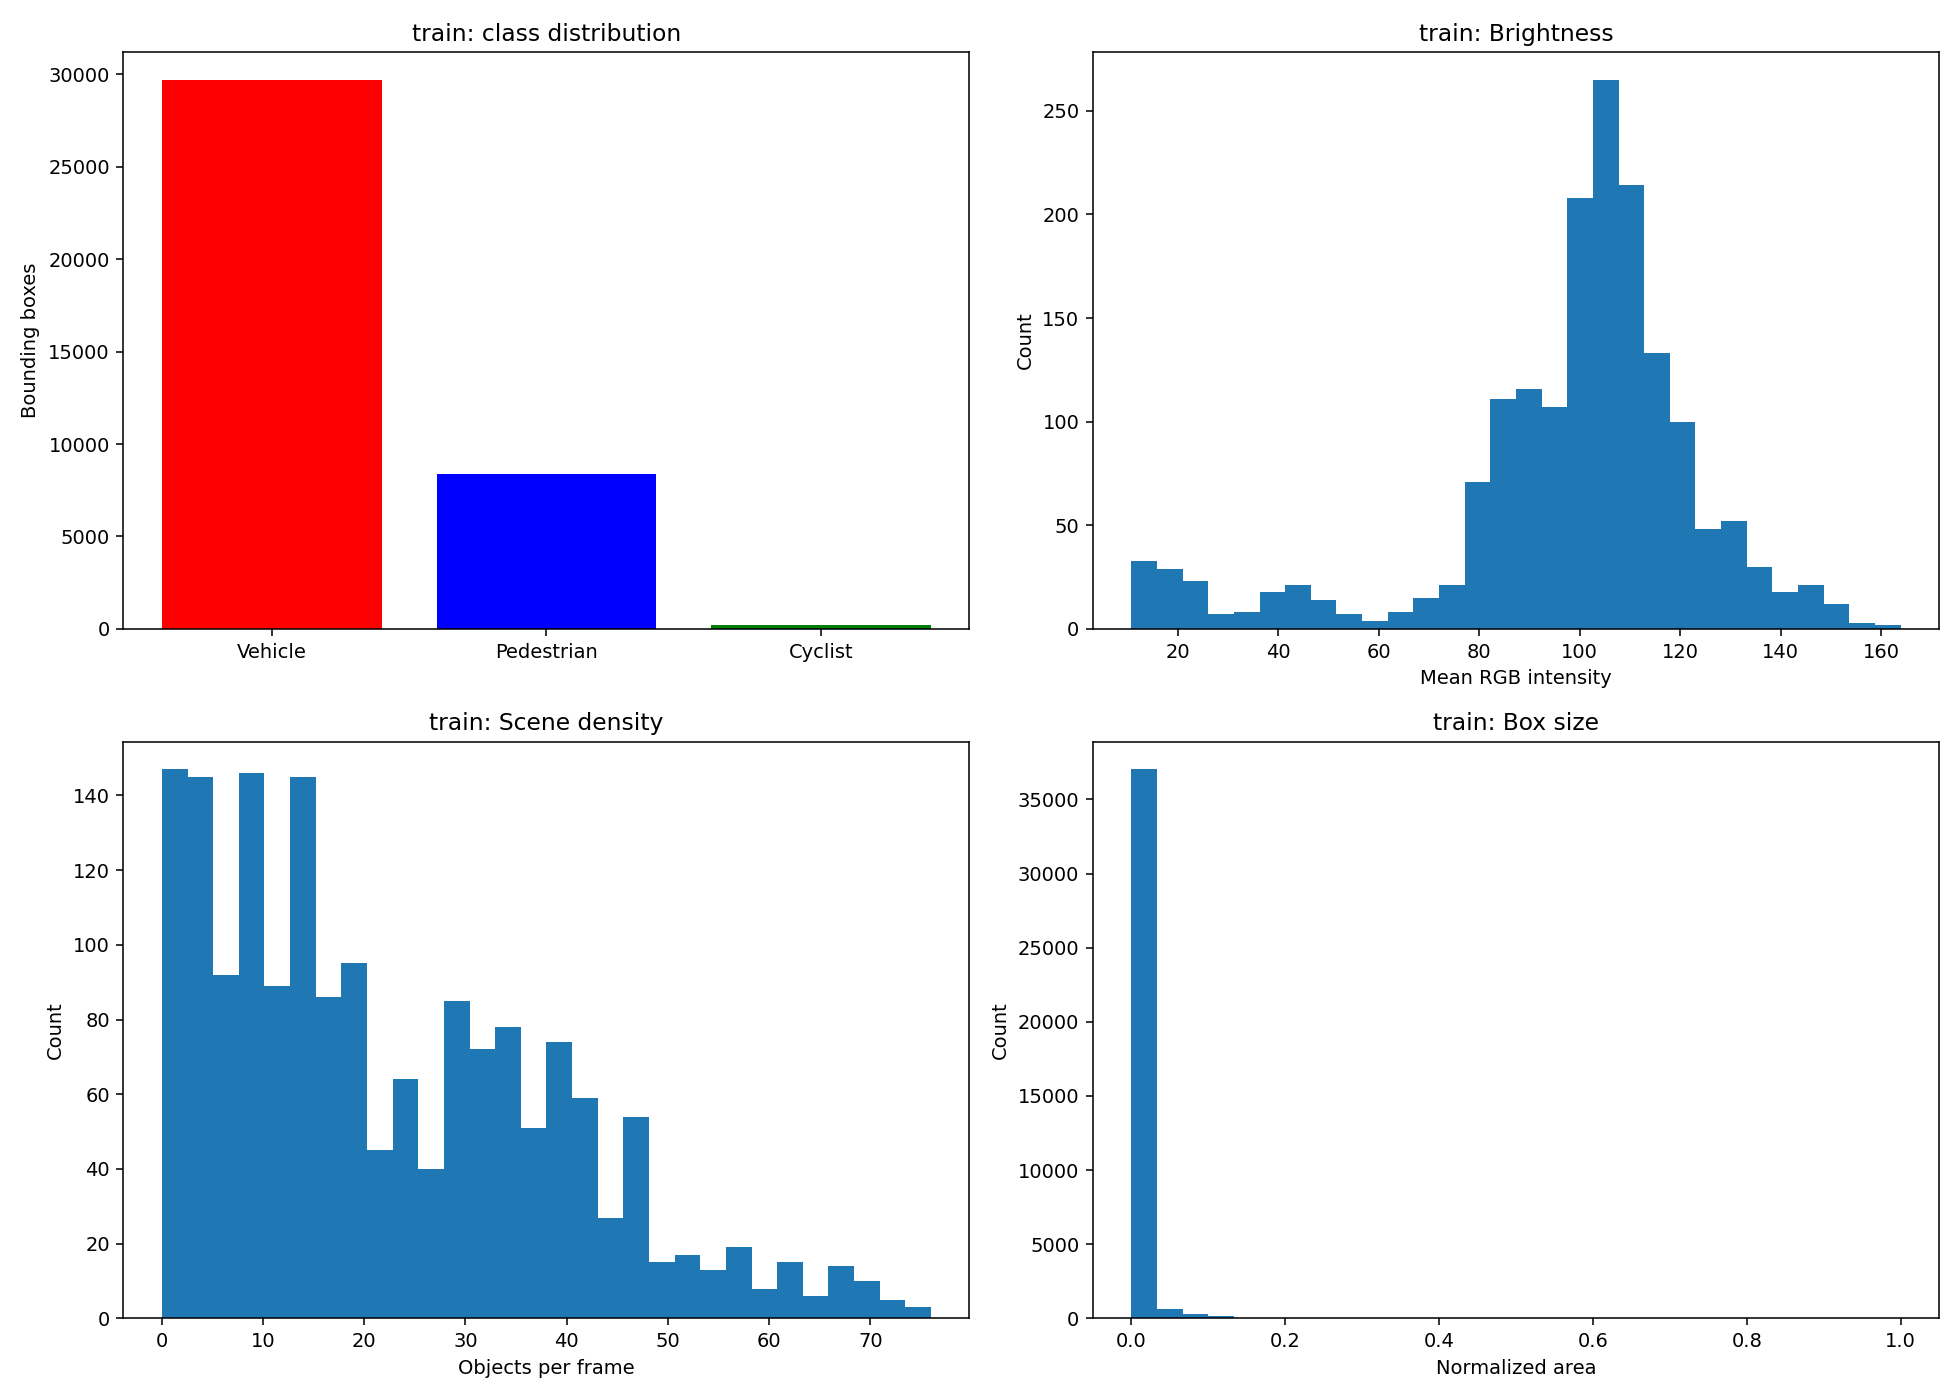

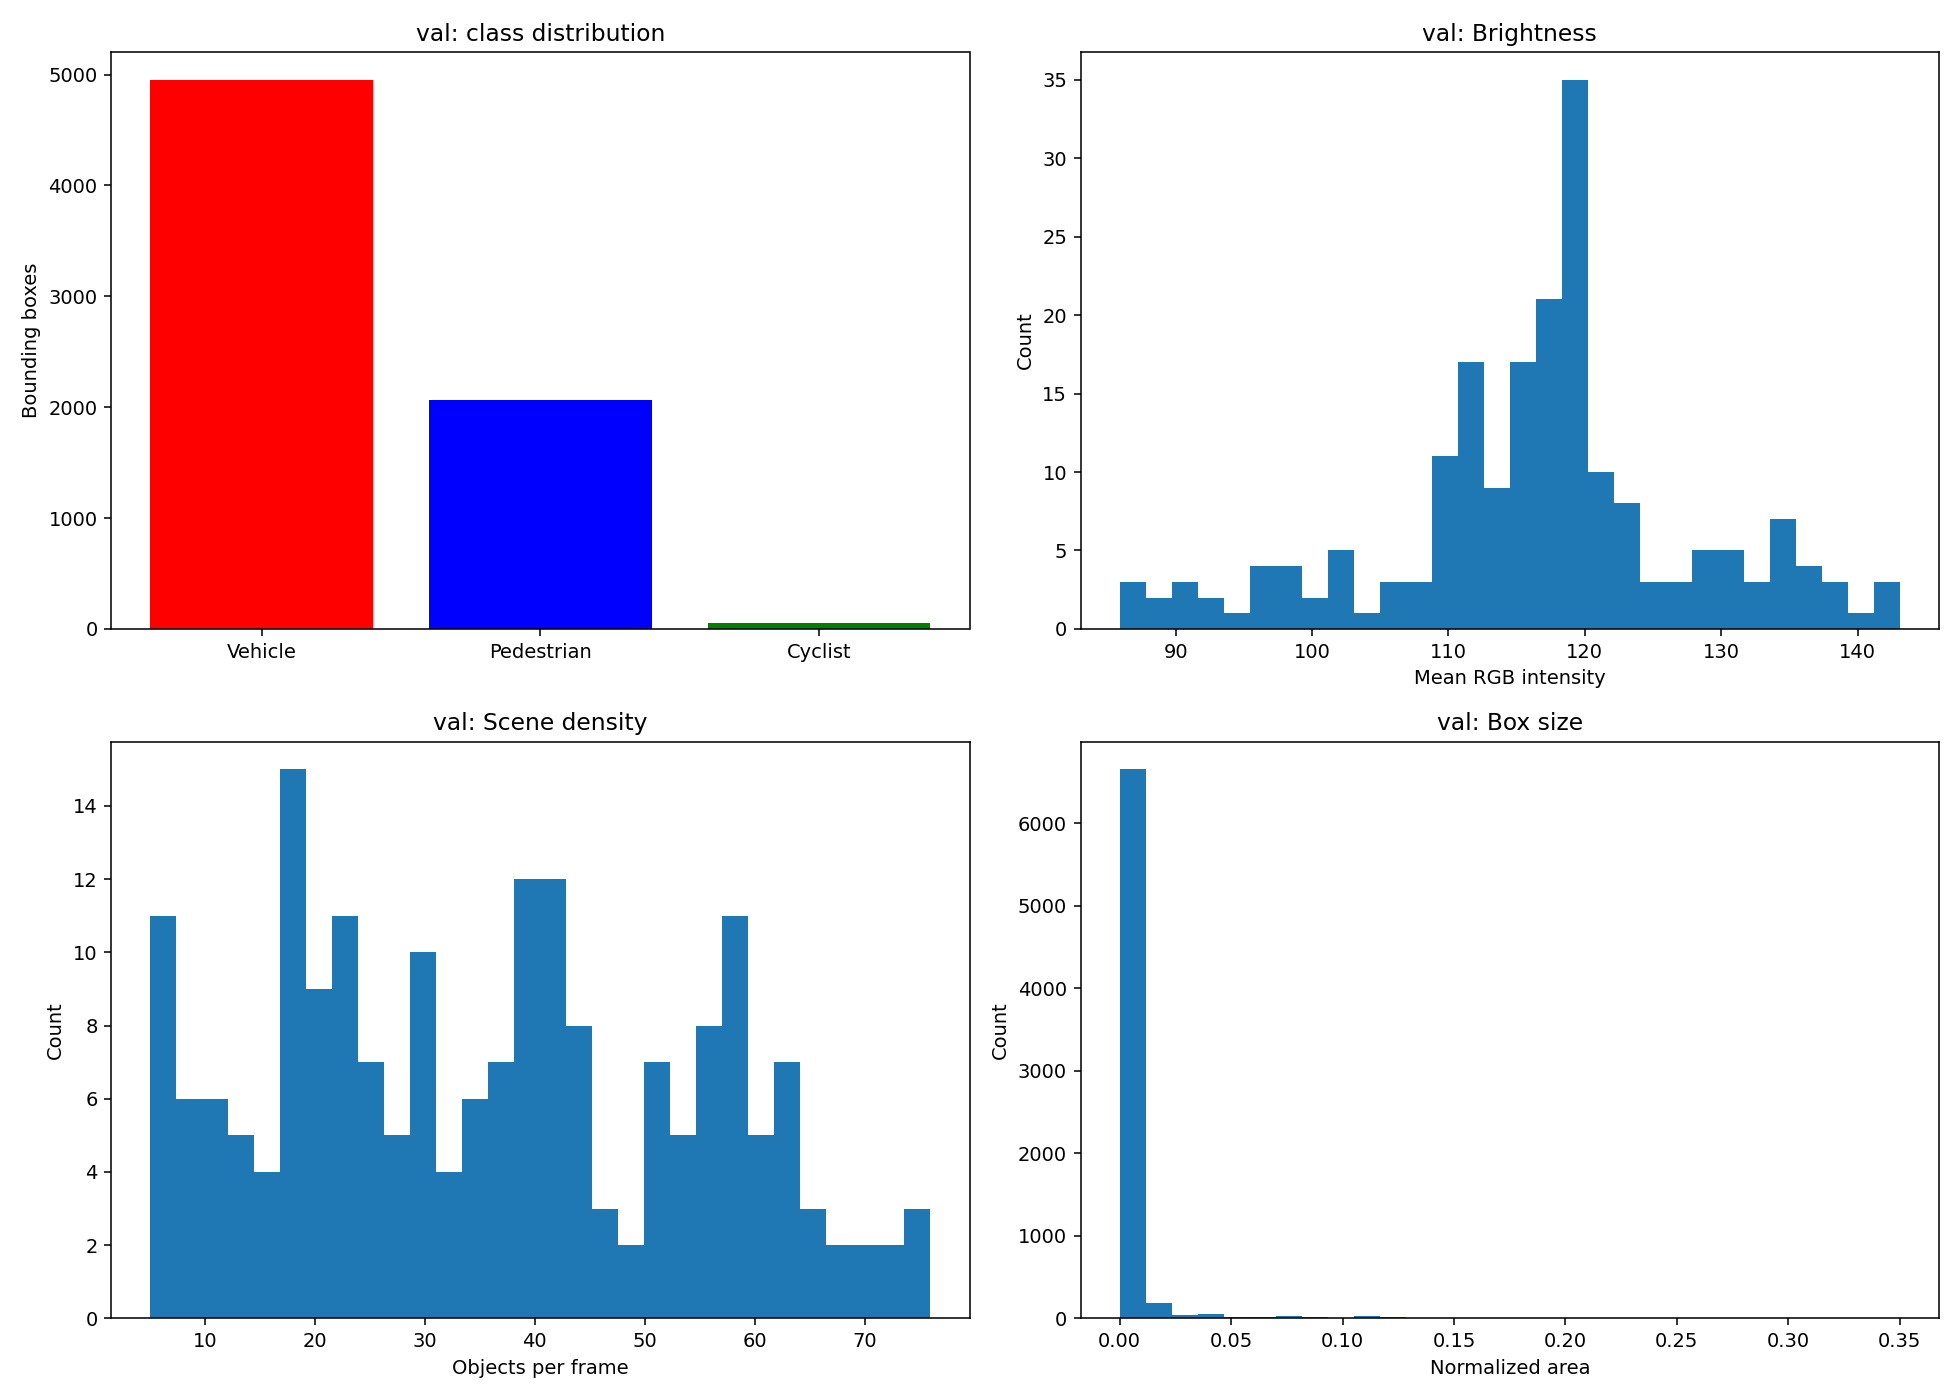

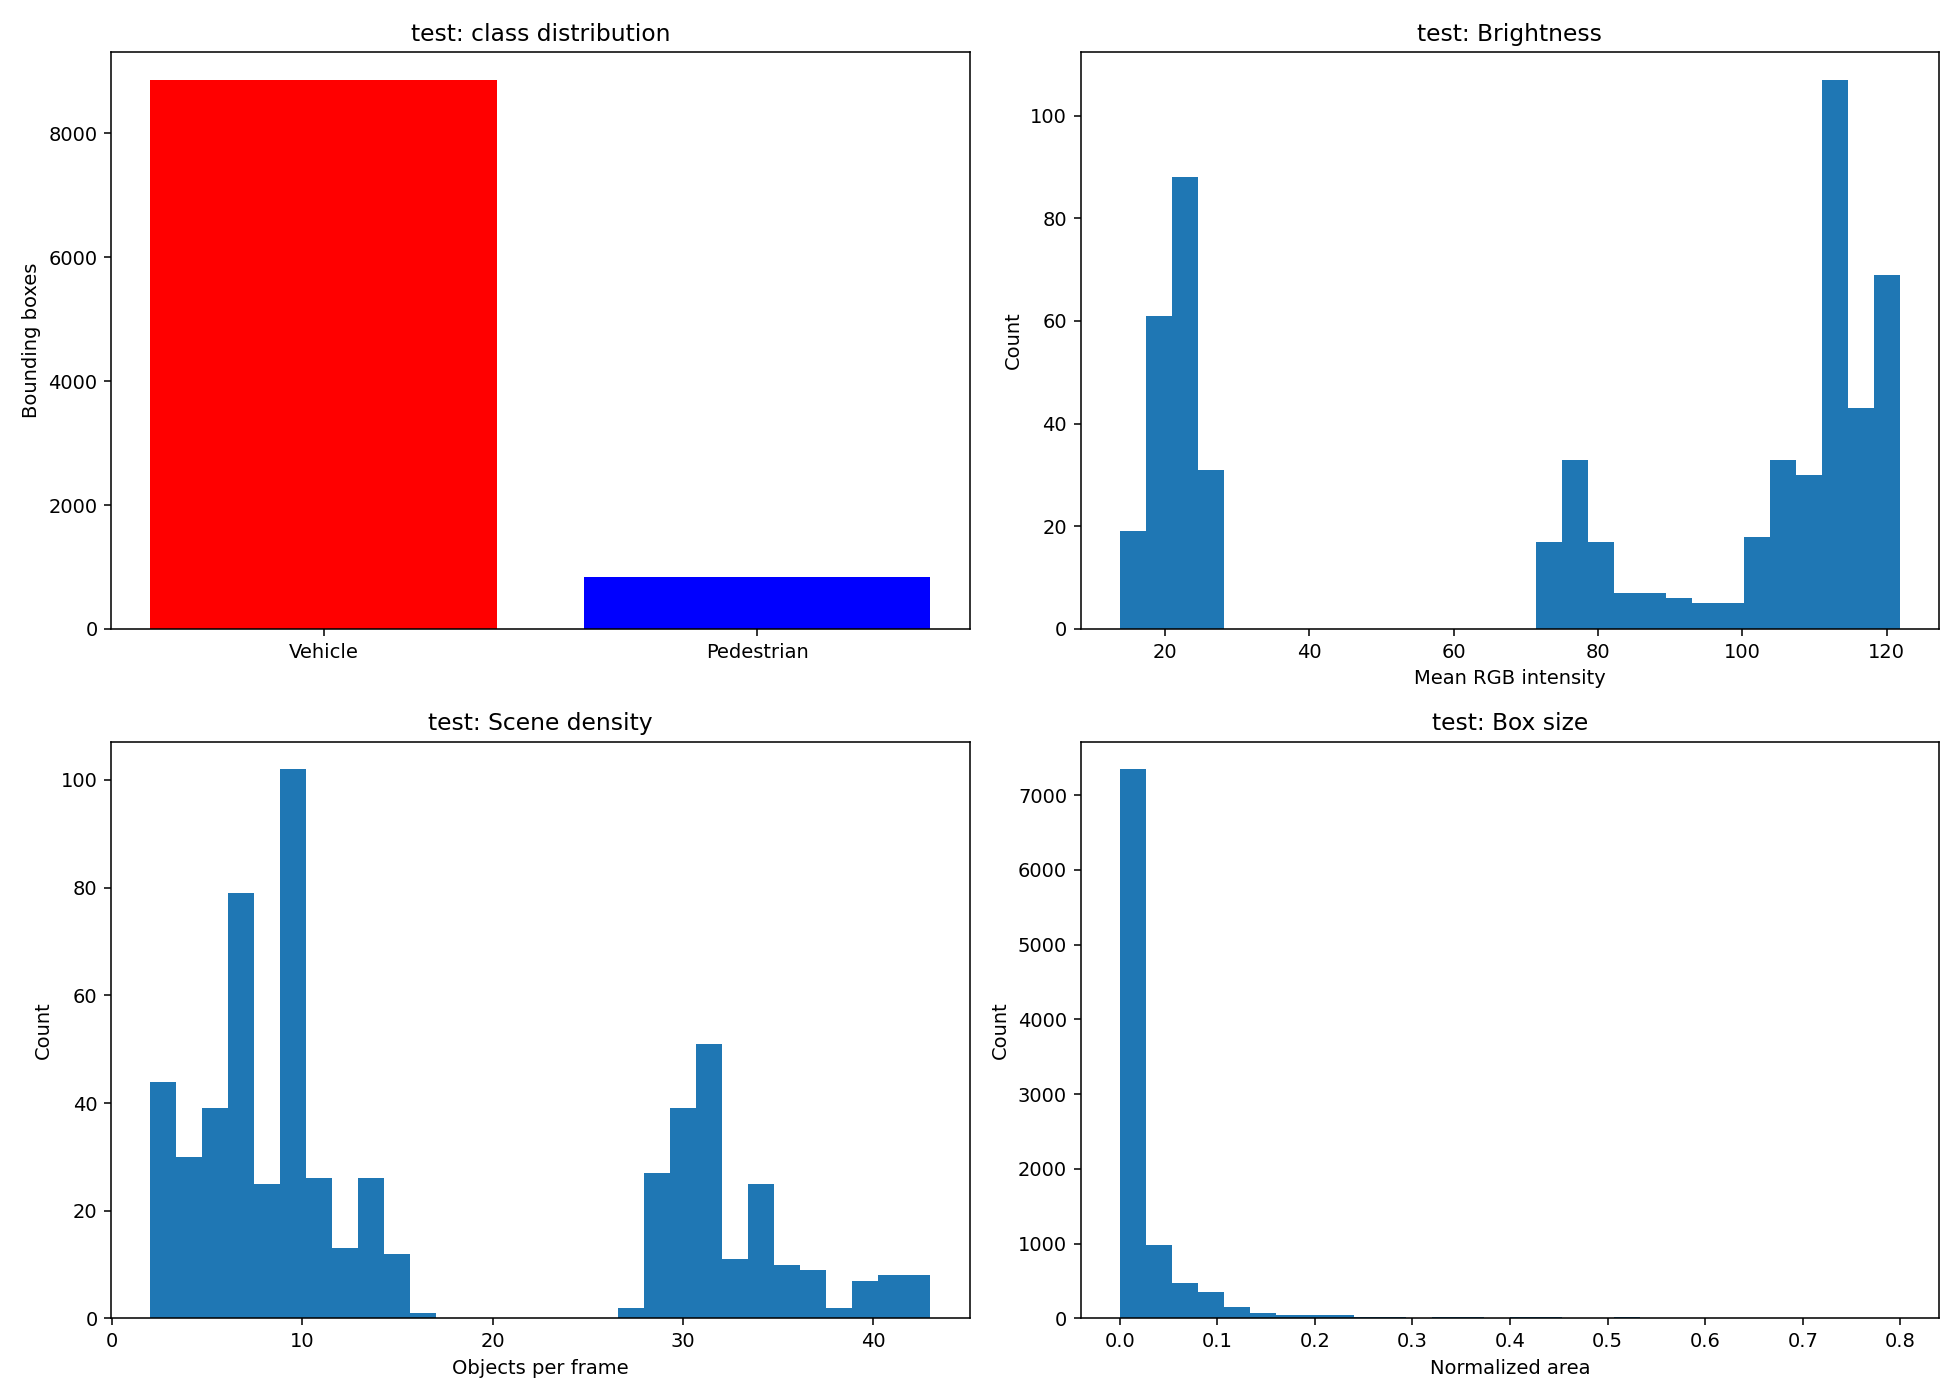

In [4]:
for split in ("train", "val", "test"):
    display(Image(filename=f"artifacts/eda/{split}_distributions.png"))

## Findings

The training split has 1,719 frames and 38,279 boxes; only 214 boxes (0.56%) are cyclists. Validation is brighter and more crowded than training, with a smaller median box area. These distribution shifts can raise validation loss. Night scenes, glare, intersections, occlusion, and distant objects are visible in the sampled images. The 596 test frames contain no cyclist labels, so this test subset cannot establish cyclist recall.

The supplied split has 86/10/3 disjoint segment files. This is a single holdout evaluation, not k-fold cross-validation. No test frames are used for optimization or checkpoint selection. Split filenames and exact measurements are saved in `artifacts/eda/statistics.json`.